In [1]:
########## Redundancy using Chi2 test #############
import numpy as np
from scipy.stats import chi2_contingency

# Contingency table
data = np.array([[10, 20, 30],
                 [6, 9, 17]])

chi2, p, dof, expected = chi2_contingency(data)

print("Chi-square Statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)
print("Expected values:\n", expected)

Chi-square Statistic: 0.27157465150403504
p-value: 0.873028283380073
Degrees of freedom: 2
Expected values:
 [[10.43478261 18.91304348 30.65217391]
 [ 5.56521739 10.08695652 16.34782609]]


In [2]:
import numpy as np
from scipy.stats import chi2, chi2_contingency

#Observed data
table = np.array([[250, 200],
                  [50, 1000]])

# Chi-square test
chi2_calc, p, dof, expected = chi2_contingency(table)

#Critical chi-square value at alpha=0.01
alpha = 0.01
chi2_critical = chi2.ppf(1 - alpha, dof)

# Print results
print("Chi-square calculated =", chi2_calc)
print("Chi-square critical (tabular) =", chi2_critical)
print("Degrees of freedom =", dof)
#print("p-value =", p)

#Compare
if chi2_calc > chi2_critical:
    print("Reject H0: Gender and preference are not independent.")
else:
    print("Fail to reject H0: No significant relationship.")

Chi-square calculated = 504.76686507936506
Chi-square critical (tabular) = 6.6348966010212145
Degrees of freedom = 1
Reject H0: Gender and preference are not independent.


In [2]:
###################### Feature Selection using Mutual Information ###############################
######### I(X;Y) = H(X) - H(X|Y) #####################
import pandas as pd

df = pd.read_csv('iris.csv', header=None)
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('species', axis=1),
    df['species'],
    test_size=0.3,
    random_state=42
)
X_train.head()

,sepal_length,sepal_width,petal_length,petal_width
81,5.5,2.4,3.7,1.0
133,6.3,2.8,5.1,1.5
137,6.4,3.1,5.5,1.8
75,6.6,3.0,4.4,1.4
109,7.2,3.6,6.1,2.5


In [4]:
from sklearn.feature_selection import mutual_info_classif # Mutual Information
import pandas as pd

mi_scores = mutual_info_classif(X_train, y_train)

mi_series = pd.Series(mi_scores, index=X_train.columns)
mi_series.sort_values(ascending=False)

petal_length    0.958994
petal_width     0.944072
sepal_length    0.500464
sepal_width     0.216586
dtype: float64

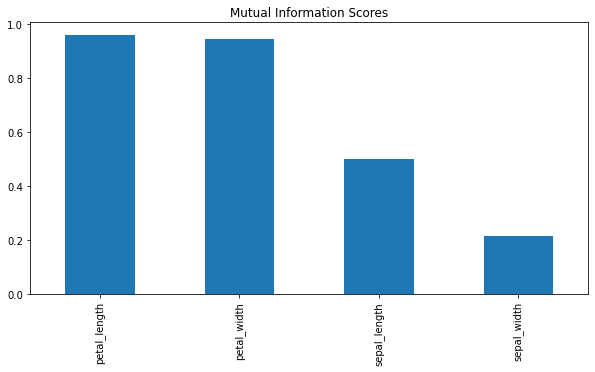

In [5]:
import matplotlib.pyplot as plt

mi_series.sort_values(ascending=False).plot.bar(figsize=(10,5), title="Mutual Information Scores")
plt.show()

In [7]:
############## Feature Selection using Chi-Square #############

import seaborn as sns

df2=sns.load_dataset('titanic')

df2.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [9]:
df2['sex'].unique() #only considering 'sex','alone','embarked','pclass','survided'

array(['male', 'female'], dtype=object)

In [10]:
# perform label encoding
import numpy as np
df2['sex']=np.where(df2['sex']=="male",1,0)

In [11]:
# perform label encoding on alone
df2['alone']=np.where(df2['alone']==True,1,0)

In [12]:
# perform label encoding
ordinal_label = {k: i for i, k in enumerate(df2['embarked'].unique(), 0)}
df2['embarked'] = df2['embarked'].map(ordinal_label)

In [13]:
# train Test split is usually done to avaoid overfitting
from sklearn.model_selection import train_test_split

X_train2,X_test2,y_train2,y_test2=train_test_split(df2[['sex','embarked','alone','pclass']],
                                               df2['survived'],test_size=0.3,random_state=100)

In [14]:
X_train2.head()

,sex,embarked,alone,pclass
69,1,0,0,3
85,0,0,0,3
794,1,0,1,3
161,0,0,1,2
815,1,0,1,1


In [15]:
# Perform chi2 test
# chi2 returns 2 values
# Fscore and the pvalue
from sklearn.feature_selection import chi2
f_p_values=chi2(X_train2,y_train2)

In [16]:
p_values=pd.Series(f_p_values[1])
p_values.index=X_train2.columns
p_values

sex         5.306038e-16
embarked    5.999221e-03
alone       9.696105e-04
pclass      2.755149e-06
dtype: float64

In [17]:
p_values.sort_index(ascending=False)

sex         5.306038e-16
pclass      2.755149e-06
embarked    5.999221e-03
alone       9.696105e-04
dtype: float64

In [173]:
# Observation
# Sex Column is the most important column when compared to the output feature Survived

In [32]:
# ============================================================
# RELIEF FEATURE SELECTION
# Dataset: Breast Cancer Wisconsin
# ============================================================

import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import pairwise_distances

# dataset

data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names

print("Number of samples :", X.shape[0])
print("Number of features:", X.shape[1])


# Normalize features as Relief uses distances

scaler = MinMaxScaler()
X = scaler.fit_transform(X)


# Relief Algorithm

m = len(X)

weights = np.zeros(X.shape[1])

# Calculate distances between all samples
distances = pairwise_distances(X, metric='euclidean')

for i in range(m):

    # --------------------------------------------------------
    # Find nearest HIT
    # Same class as sample i
    # --------------------------------------------------------

    same_class = np.where(y == y[i])[0]

    # Remove the sample itself
    same_class = same_class[same_class != i]

    hit = same_class[
        np.argmin(distances[i, same_class])
    ]


    # --------------------------------------------------------
    # Find nearest MISS
    # Different class from sample i
    # --------------------------------------------------------

    different_class = np.where(y != y[i])[0]

    miss = different_class[
        np.argmin(distances[i, different_class])
    ]


    # --------------------------------------------------------
    # Update feature weights
    # --------------------------------------------------------

    weights -= (X[i] - X[hit])**2 / m

    weights += (X[i] - X[miss])**2 / m



# Feature weights

results = pd.DataFrame({
    'Feature': feature_names,
    'Relief Weight': weights
})

results = results.sort_values(
    'Relief Weight',
    ascending=False
)

print("\nFeature Scores:")
print(results.head(10))

Number of samples : 569
Number of features: 30

Feature Ranking:
                 Feature  Relief Weight
27  worst concave points       0.025216
20          worst radius       0.022115
22       worst perimeter       0.019943
7    mean concave points       0.019477
21         worst texture       0.018194
23            worst area       0.016434
2         mean perimeter       0.015764
0            mean radius       0.015761
3              mean area       0.015182
6         mean concavity       0.012286


In [18]:
pip install skrebate # ReliefF algorithm, special library installed

Note: you may need to restart the kernel to use updated packages.


In [19]:
#Feature Selection for Iris Dataset using ReliefF

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from skrebate import ReliefF
import pandas as pd
import matplotlib.pyplot as plt


In [20]:
#Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names

In [21]:
#Scale the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [22]:
#Apply ReliefF
relief = ReliefF(n_neighbors=10)
relief.fit(X_scaled, y)

ReliefF(n_neighbors=10)

In [23]:
#Display feature importance
scores = pd.DataFrame({
    'Feature': feature_names,
    'ReliefF_Score': relief.feature_importances_
}).sort_values(by='ReliefF_Score', ascending=False)

print(scores)

             Feature  ReliefF_Score
3   petal width (cm)       0.375472
2  petal length (cm)       0.358989
0  sepal length (cm)       0.139796
1   sepal width (cm)       0.122639


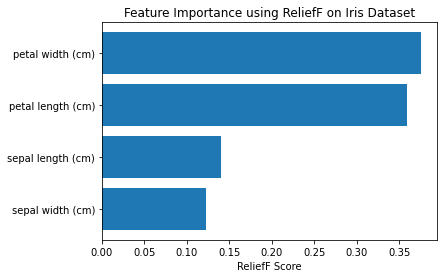

In [24]:
plt.barh(scores['Feature'], scores['ReliefF_Score'])
plt.gca().invert_yaxis()
plt.xlabel("ReliefF Score")
plt.title("Feature Importance using ReliefF on Iris Dataset")
plt.show()

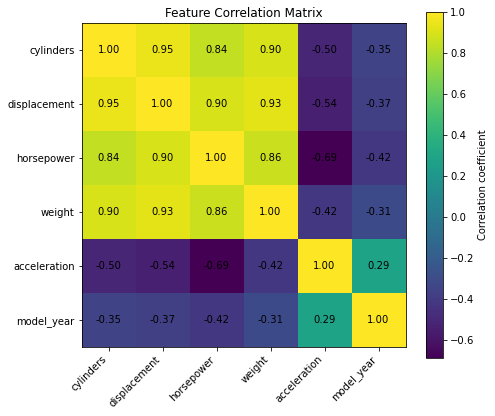


Highly correlated features:
cylinders <--> displacement : 0.95
cylinders <--> weight : 0.9
displacement <--> horsepower : 0.9
displacement <--> weight : 0.93
horsepower <--> weight : 0.86


In [30]:
# ============================================================
# CORRELATION-BASED FEATURE SELECTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    'mpg',
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model_year',
    'origin',
    'car_name'
]

data = pd.read_csv(
    url,
    sep=r'\s+',
    names=columns,
    na_values='?'
)

data = data.dropna()



X = data[
    [
        'cylinders',
        'displacement',
        'horsepower',
        'weight',
        'acceleration',
        'model_year'
    ]
]


# Calculate Correlation
corr = X.corr()

# Plot Correlation Matrix
plt.figure(figsize=(7, 6))

plt.imshow(corr)

plt.colorbar(label='Correlation coefficient')

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i,j]:.2f}",
            ha='center',
            va='center'
        )

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


#Find highly correlated feature pairs

threshold = 0.85

print("\nHighly correlated features:")

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):

        if abs(corr.iloc[i, j]) > threshold:

            print(
                corr.columns[i],
                "<-->",
                corr.columns[j],
                ":",
                round(corr.iloc[i, j], 2)
            )